In [77]:
import csv
from pathlib import Path

import pandas as pd

# Initial CSV reading for inspection.
train = pd.read_csv(
    "train.csv",
    sep=";",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)

print("Dataset shape:", train.shape)
display(train.head())

Dataset shape: (2616, 5)


,medical_specialty,description,sample_name,transcription,keywords
0,Cardiovascular-Pulmonary,"Chest pain, possible syncopal spells. She ha...",Chest Pain - Cardiac Consult,"REASON FOR REFERRAL: Chest pain, possible syn...","cardiovascular / pulmonary, chest pain, syncop..."
1,Cardiovascular-Pulmonary,"The patient is 14 months old, comes in with a ...",Difficulty Breathing - ER Visit,"HISTORY: The patient is 14 months old, comes ...",
2,Cardiovascular-Pulmonary,"Fiberoptic bronchoscopy, diagnostic. Hemopty...",Fiberoptic Bronchoscopy - 1,"PREOPERATIVE DIAGNOSIS:1. Hemoptysis.,2. His...","cardiovascular / pulmonary, hemoptysis, lung c..."
3,Cardiovascular-Pulmonary,Left lower extremity venous Doppler ultrasound,Lower Extremity Venous Doppler,LEFT LOWER EXTREMITY VENOUS DOPPLER ULTRASOUND...,"cardiovascular / pulmonary, popliteal veins, s..."
4,Cardiovascular-Pulmonary,The patient was admitted after undergoing a d...,Discharge Summary - Respiratory Failure,DISCHARGE DIAGNOSIS:1. Respiratory failure im...,"cardiovascular / pulmonary, respiratory failur..."


In [78]:
specialties = {
    "Cardiovascular-Pulmonary", "Dermatology", "Gastroenterology",
    "General Medicine", "Neurology", "Neurosurgery",
    "Obstetrics-Gynecology", "Ophthalmology", "Orthopedic",
    "Psychiatry-Psychology", "Radiology", "Surgery"
}

raw_lines = Path("train.csv").read_text(encoding="utf-8-sig").splitlines()

# Check labels and field counts without changing the data.
checks = []

for number, line in enumerate(raw_lines[1:], start=2):
    if not line.strip():
        continue

    fields = next(csv.reader([line], delimiter=";"))

    checks.append({
        "line": number,
        "valid_label": fields[0].strip() in specialties,
        "fields": len(fields)
    })

line_checks = pd.DataFrame(checks)

display(
    line_checks.groupby(["valid_label", "fields"])
    .size()
    .reset_index(name="count")
)

# Show lines that need inspection.
display(
    line_checks.loc[
        ~line_checks["valid_label"] | line_checks["fields"].ne(5)
    ]
)

,valid_label,fields,count
0,False,5,3
1,True,2,7
2,True,5,2656
3,True,7,6


,line,valid_label,fields
159,161,True,2
161,163,True,7
712,714,True,2
945,947,True,2
959,961,True,7
960,962,False,5
1086,1088,True,2
1094,1096,True,7
2087,2089,True,2
2098,2100,True,7


In [79]:
# Inspect each field in the flagged lines.
flagged = line_checks.loc[
    ~line_checks["valid_label"] | line_checks["fields"].ne(5)
]

for number in flagged["line"]:
    fields = next(csv.reader([raw_lines[number - 1]], delimiter=";"))

    print(f"\n--- Line {number}: {len(fields)} fields ---")

    for position, value in enumerate(fields):
        print(f"Field {position}: {value[:200]!r}")


--- Line 161: 2 fields ---
Field 0: 'Cardiovascular-Pulmonary'
Field 1: 'Seizure, hypoglycemia, anemia, dyspnea, edema. colon cancer status post right hemicolectomy, hospital-acquired pneumonia, '

--- Line 163: 7 fields ---
Field 0: 'Psychiatry-Psychology'
Field 1: ' The patient comes in for a neurology consultation regarding her difficult headaches, tunnel vision, and dizziness. '
Field 2: 'Neuropsychological Evaluation - 5'
Field 3: 'PROBLEMS AND ISSUES:1.  Headaches, nausea, and dizziness, consistent with a diagnosis of vestibular migraine, recommend amitriptyline for prophylactic treatment and Motrin for abortive treatment.,2.  '
Field 4: 'psychiatry / psychology, nausea, dizziness, migraine, peripheral neuropathy, diabetic neuropathy, neuropathy, positional vertigo, photophobia and dizziness, neurology consultation, tunnel vision, vest'
Field 5: ''
Field 6: ''

--- Line 714: 2 fields ---
Field 0: 'General Medicine'
Field 1: 'Seizure, hypoglycemia, anemia, dyspnea, edema. colon c

In [80]:
columns = [
    "medical_specialty", "description",
    "sample_name", "transcription", "keywords"
]

continuations = {962: 961, 2101: 2100, 2338: 2337}

records = []
record_lines = []
corrections = []

for number, line in enumerate(raw_lines[1:], start=2):
    if not line.strip():
        continue

    fields = next(csv.reader([line], delimiter=";"))
    label = fields[0].strip()

    if label in specialties:
        fields[0] = label

        if len(fields) == 2:
            fields += ["", "", ""]
            corrections.append({
                "line": number,
                "action": "Filled three missing fields"
            })

        elif len(fields) > 5 and all(
            not value.strip() for value in fields[5:]
        ):
            fields = fields[:5]
            corrections.append({
                "line": number,
                "action": "Removed empty extra fields"
            })

        elif len(fields) != 5:
            raise ValueError(f"Unexpected field count on line {number}")

        records.append(fields)
        record_lines.append(number)

    elif number in continuations:
        if (
            not records
            or record_lines[-1] != continuations[number]
            or len(fields) != 5
            or any(value.strip() for value in fields[1:])
        ):
            raise ValueError(f"Unexpected continuation on line {number}")

        # Keep both text fragments, separated by a space.
        records[-1][3] = (
            records[-1][3].rstrip() + " " + fields[0].lstrip()
        )

        corrections.append({
            "line": number,
            "action": f"Attached transcription to line {record_lines[-1]}"
        })

    else:
        raise ValueError(f"Unrecognized record on line {number}")

train = pd.DataFrame(records, columns=columns)
correction_log = pd.DataFrame(corrections)

In [81]:
# Check the expected structure and correction counts.
assert train.shape == (2669, 5)
assert train.columns.tolist() == columns
assert train["medical_specialty"].isin(specialties).all()
assert train["medical_specialty"].nunique() == 12
assert not train.isna().any().any()

assert (
    correction_log["action"].eq("Filled three missing fields").sum() == 7
)
assert (
    correction_log["action"].eq("Removed empty extra fields").sum() == 6
)
assert (
    correction_log["action"].str.startswith("Attached transcription").sum() == 3
)

# Verify that each continuation was preserved in its transcription.
for continuation, original in continuations.items():
    fragment = next(
        csv.reader([raw_lines[continuation - 1]], delimiter=";")
    )[0].lstrip()

    position = record_lines.index(original)
    assert train.iloc[position]["transcription"].endswith(fragment)

print("Structural checks passed.")
print("Dataset shape:", train.shape)

display(correction_log)
display(
    train.iloc[
        [record_lines.index(number) for number in continuations.values()]
    ][["medical_specialty", "sample_name", "transcription"]]
)

Structural checks passed.
Dataset shape: (2669, 5)


,line,action
0,161,Filled three missing fields
1,163,Removed empty extra fields
2,714,Filled three missing fields
3,947,Filled three missing fields
4,961,Removed empty extra fields
5,962,Attached transcription to line 961
6,1088,Filled three missing fields
7,1096,Removed empty extra fields
8,2089,Filled three missing fields
9,2100,Removed empty extra fields


,medical_specialty,sample_name,transcription
959,General Medicine,Dog Bite,CHIEF COMPLAINT: Dog bite to his right lower ...
2097,Neurology,TIA & Lumbar Stenosis,CHIEF COMPLAINT: Transient visual loss lasting...
2333,Surgery,D&C & Laparoscopy - 2,PREOPERATIVE DIAGNOSIS: Incidental right adnex...


In [82]:
# Count records and calculate the percentage of each specialty.
class_counts = train["medical_specialty"].value_counts()

class_distribution = class_counts.to_frame(name="records")
class_distribution["percentage"] = (
    class_counts / len(train) * 100
).round(1)

display(class_distribution)

,records,percentage
medical_specialty,,
Surgery,893,33.5
Cardiovascular-Pulmonary,309,11.6
Orthopedic,300,11.2
Radiology,222,8.3
General Medicine,212,7.9
Gastroenterology,195,7.3
Neurology,184,6.9
Obstetrics-Gynecology,136,5.1
Neurosurgery,79,3.0


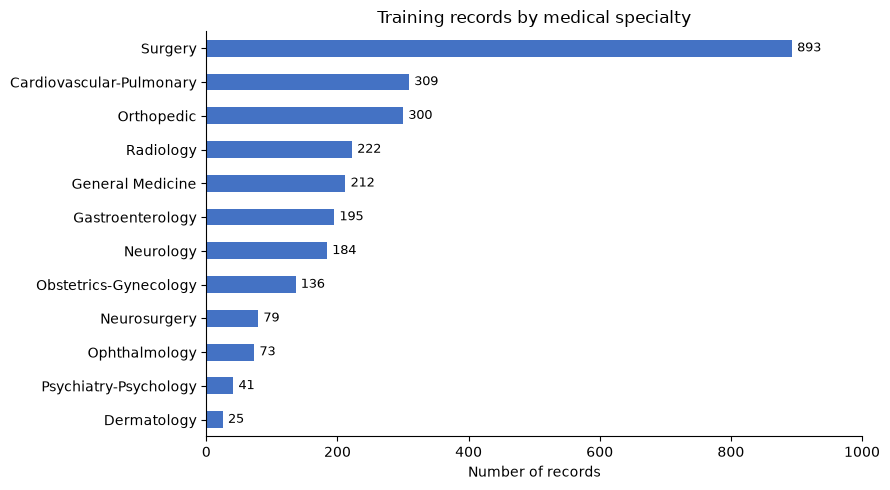

In [83]:
import matplotlib.pyplot as plt

# Plot the number of records per specialty.
counts = class_distribution["records"].sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
counts.plot.barh(ax=ax, color="#4472C4")

ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_title("Training records by medical specialty")
ax.spines[["top", "right"]].set_visible(False)

for position, count in enumerate(counts):
    ax.text(count + 8, position, str(count), va="center", fontsize=9)

ax.set_xlim(0, counts.max() * 1.12)

plt.tight_layout()
plt.show()

In [84]:
# Count empty fields, including values containing only whitespace.
empty_counts = train.apply(
    lambda column: column.str.strip().eq("").sum()
)

empty_summary = empty_counts.to_frame(name="empty_records")
empty_summary["percentage"] = (
    empty_counts / len(train) * 100
).round(1)

display(empty_summary)

,empty_records,percentage
medical_specialty,0,0.0
description,1,0.0
sample_name,7,0.3
transcription,31,1.2
keywords,450,16.9


In [85]:
# Count records sharing a non-empty transcription with a different specialty.
notes = train.loc[train["transcription"].str.strip().ne("")]

different_labels = notes.groupby("transcription")[
    "medical_specialty"
].transform("nunique").gt(1)

count = different_labels.sum()

print(
    f"Records sharing a transcription with different labels: "
    f"{count} ({count / len(train):.1%})"
)

Records sharing a transcription with different labels: 1528 (57.2%)


In [86]:
# Inspect one transcription associated with different specialties.
shared_text = notes.loc[
    different_labels, "transcription"
].iloc[0]

print("\n--- Same transcription, different specialties ---")
print("Transcription excerpt:", shared_text[:600])

display(
    train.loc[
        train["transcription"].eq(shared_text),
        ["medical_specialty", "description", "sample_name", "keywords"]
    ]
)


--- Same transcription, different specialties ---
Transcription excerpt: LEFT LOWER EXTREMITY VENOUS DOPPLER ULTRASOUND,REASON FOR EXAM: Status post delivery five weeks ago presenting with left calf pain.,INTERPRETATIONS: There was normal flow, compression and augmentation within the right common femoral, superficial femoral and popliteal veins.  Lymph nodes within the left inguinal region measure up to 1 cm in short-axis.,IMPRESSION: Lymph nodes within the left inguinal region measure up to 1 cm in short-axis, otherwise no evidence for left lower extremity venous thrombosis.


,medical_specialty,description,sample_name,keywords
3,Cardiovascular-Pulmonary,Left lower extremity venous Doppler ultrasound,Lower Extremity Venous Doppler,"cardiovascular / pulmonary, popliteal veins, s..."
1715,Radiology,Left lower extremity venous Doppler ultrasound,Lower Extremity Venous Doppler,"radiology, popliteal veins, superficial femora..."


In [87]:
# Compare the first keyword with the specialty, ignoring case and slash formatting.
first_keyword = (
    train["keywords"].str.split(",").str[0]
    .str.strip().str.lower()
    .str.replace(r"\s*/\s*", "-", regex=True)
)

labels = train["medical_specialty"].str.lower()
has_keywords = train["keywords"].str.strip().ne("")
matches = first_keyword.eq(labels)

print("Records with keywords:", has_keywords.sum())
print("Records with keywords whose first keyword matches the label:",
      (matches & has_keywords).sum())

if has_keywords.any():
    print(f"Match rate among records with keywords: {matches[has_keywords].mean():.1%}")

Records with keywords: 2219
Records with keywords whose first keyword matches the label: 2219
Match rate among records with keywords: 100.0%


In [88]:
# Check whether missing keywords are concentrated in particular specialties.
keyword_summary = (
    train.assign(missing_keywords=~has_keywords)
    .groupby("medical_specialty")
    .agg(
        records=("missing_keywords", "size"),
        missing_keywords=("missing_keywords", "sum")
    )
)

keyword_summary["missing_percentage"] = (
    keyword_summary["missing_keywords"]
    / keyword_summary["records"] * 100
).round(1)

display(keyword_summary.sort_values("missing_percentage", ascending=False))

,records,missing_keywords,missing_percentage
medical_specialty,,,
Psychiatry-Psychology,41,27,65.9
General Medicine,212,90,42.5
Neurology,184,50,27.2
Cardiovascular-Pulmonary,309,79,25.6
Dermatology,25,5,20.0
Obstetrics-Gynecology,136,24,17.6
Neurosurgery,79,13,16.5
Orthopedic,300,48,16.0
Gastroenterology,195,29,14.9


In [89]:
# Save the corrected dataset and the record of structural corrections.
train.to_csv(
    "train_clean.csv",
    sep=";",
    index=False,
    encoding="utf-8"
)

print("Saved train_clean.csv")

Saved train_clean.csv
